<a href="https://colab.research.google.com/github/brunobro/chromium-stress-in-lettuce-and-spinach/blob/main/ChromiumStressInLettuceAndSpinach.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Identifies Metabolic Signatures of Chromium Stress in Lettuce and Spinach: Implications for Food Safety Monitoring

Heavy metal contamination threatens the safe production of leafy vegetables. Chromium (Cr), particularly in its hexavalent form, is highly toxic, causing metabolic disruption, photosynthetic impairment, oxidative damage, and growth inhibition. This study investigated the metabolic and physiological responses of Lactuca sativa and Spinacia oleracea under Cr stress, using machine learning to identify key biochemical predictors and relate metabolic profiles to physiological performance. Random Forest analysis identified fatty acids, particularly palmitoleic, stearic, myristic, and oleic acids, as the most informative variables for discriminating control and Cr-stressed plants. Organic acids and soluble sugars also contributed to treatment discrimination, indicating the importance of primary metabolic adjustments in responses to Cr toxicity. Support Vector Regression showed high agreement between observed and fitted values for photosynthetic rate, Rubisco activity, and fresh biomass, whereas dry biomass was poorly explained by the metabolic profile, reflecting the complexity of cumulative growth responses. The two species displayed contrasting, species-specific metabolic patterns. These findings demonstrate the potential of integrating biochemical profiling with machine learning to identify informative signatures of heavy metal stress, providing a basis for screening strategies that support food safety surveillance and safer horticultural production.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import r2_score

df = pd.read_excel("data.xlsx")
df.columns = df.columns.str.strip()

drop_cols = ['Treatment', 'Repetition', 'Plant', 'Plant Abbr']
targets_reg = ['Fresh Weight', 'Dry Weight', 'Rubisco', 'Photosynethsis']

X = df.drop(columns=drop_cols + targets_reg)
y_class = df['Treatment']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled_df_info = X_scaled_df.copy()
X_scaled_df_info['Plant Abbr'] = df['Plant Abbr']
X_scaled_df_info['Treatment'] = df['Treatment']

In [3]:
X_scaled_df_info

,Glucose,Fructose,Sucrose,Oxalic,Malic,Succinic,Citric,Isobutyric,Fumaric,Myristic,...,Pentacosanoic,Palmitoleic,Heptadecenoic,Oleic,Linoleic,Linolenic,Eicosenoic,Tetracosenoic,Plant Abbr,Treatment
0,-1.088191,-1.213017,-0.649523,-1.395239,-0.766814,-1.169416,-1.502565,-0.137587,-0.502699,-1.098171,...,-0.433087,-0.829245,-1.015374,0.270433,-0.588059,-0.880884,-1.618066,2.205165,AT,Control
1,0.632062,-0.307949,-0.562340,-0.438812,0.073700,-1.061387,-0.433490,0.909161,0.722188,-0.550212,...,-0.027023,1.011633,0.099634,-1.064612,-0.087901,-0.482822,0.067189,-0.419486,AT,Control
2,2.352315,0.597119,-0.851246,0.517615,0.914213,-0.953357,0.635585,1.955909,1.947074,-0.002253,...,0.379040,-0.917984,1.214642,-0.530146,0.412256,-0.084760,1.752444,-0.106791,AT,Control
3,0.065175,-1.513875,0.452814,-1.047531,-0.685341,0.621882,-0.846629,0.313287,0.290209,-0.978229,...,-0.786713,-1.250168,-1.265911,-0.236986,-0.918475,-1.041295,-1.188759,-1.101844,SO,Control
4,-0.244915,-0.473444,-0.873341,-0.965411,-0.985397,0.531817,-0.916787,-0.247790,-0.394780,-0.948237,...,-0.663269,-0.783369,-0.853114,-0.167491,-0.988430,0.795384,-1.106482,-1.061742,SO,Control
5,-0.555004,0.566987,-0.152054,-0.883290,-1.285454,0.441753,-0.986944,-0.808867,-1.079768,-0.918245,...,-0.539826,-0.316571,-0.440316,-1.967508,-1.058385,2.632063,0.562672,-1.021640,SO,Control
6,-0.555330,-0.287526,-0.651021,0.068132,-0.396793,-0.944048,0.079778,-1.360990,-1.165323,-0.168722,...,-0.341776,-0.094806,-0.661705,0.628678,-0.202195,-0.778897,-0.256299,-0.540620,AT,Chrome
7,-0.748700,-0.028055,-0.664120,0.650960,-0.085904,-0.765865,0.679694,-1.134894,-0.851944,0.115633,...,-0.058963,0.648244,0.548940,0.941523,0.113640,-0.520305,1.228377,0.156960,AT,Chrome
8,-0.942070,0.231415,-0.853871,1.233787,0.224986,-0.587683,1.279611,-0.908797,-0.538564,0.399987,...,3.119563,1.391294,1.759585,-0.615144,2.009344,0.911628,0.459092,0.854540,AT,Chrome
9,-0.725206,-0.793228,1.621667,-0.497827,-0.464695,0.634102,-0.587250,-0.495043,-0.664879,0.420096,...,-0.660612,-0.120640,-1.019936,0.466841,-0.622907,-0.698014,-0.941060,-0.694134,SO,Chrome


In [4]:
X_scaled_df_info[X_scaled_df_info['Plant Abbr'] == 'AT']

,Glucose,Fructose,Sucrose,Oxalic,Malic,Succinic,Citric,Isobutyric,Fumaric,Myristic,...,Pentacosanoic,Palmitoleic,Heptadecenoic,Oleic,Linoleic,Linolenic,Eicosenoic,Tetracosenoic,Plant Abbr,Treatment
0,-1.088191,-1.213017,-0.649523,-1.395239,-0.766814,-1.169416,-1.502565,-0.137587,-0.502699,-1.098171,...,-0.433087,-0.829245,-1.015374,0.270433,-0.588059,-0.880884,-1.618066,2.205165,AT,Control
1,0.632062,-0.307949,-0.562340,-0.438812,0.073700,-1.061387,-0.433490,0.909161,0.722188,-0.550212,...,-0.027023,1.011633,0.099634,-1.064612,-0.087901,-0.482822,0.067189,-0.419486,AT,Control
2,2.352315,0.597119,-0.851246,0.517615,0.914213,-0.953357,0.635585,1.955909,1.947074,-0.002253,...,0.379040,-0.917984,1.214642,-0.530146,0.412256,-0.084760,1.752444,-0.106791,AT,Control
6,-0.555330,-0.287526,-0.651021,0.068132,-0.396793,-0.944048,0.079778,-1.360990,-1.165323,-0.168722,...,-0.341776,-0.094806,-0.661705,0.628678,-0.202195,-0.778897,-0.256299,-0.540620,AT,Chrome
7,-0.748700,-0.028055,-0.664120,0.650960,-0.085904,-0.765865,0.679694,-1.134894,-0.851944,0.115633,...,-0.058963,0.648244,0.548940,0.941523,0.113640,-0.520305,1.228377,0.156960,AT,Chrome
8,-0.942070,0.231415,-0.853871,1.233787,0.224986,-0.587683,1.279611,-0.908797,-0.538564,0.399987,...,3.119563,1.391294,1.759585,-0.615144,2.009344,0.911628,0.459092,0.854540,AT,Chrome


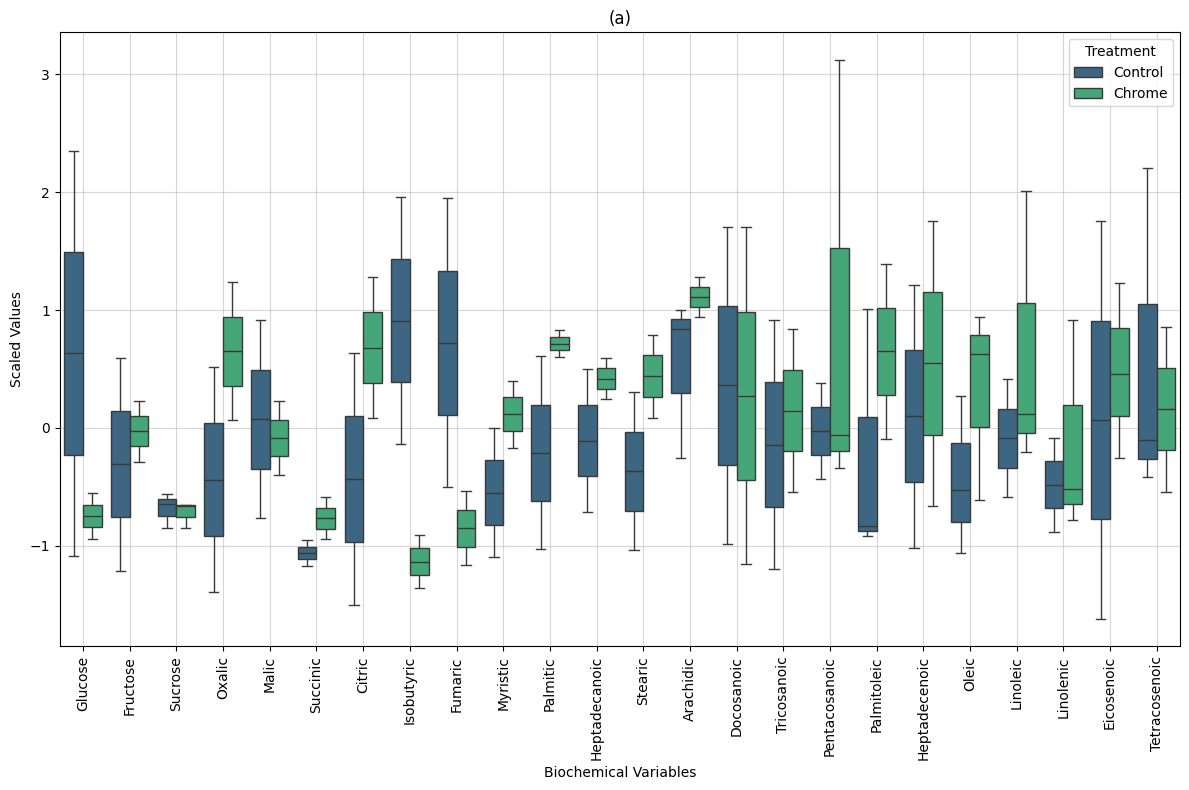

In [5]:
plt.figure(figsize=(12, 8))

# Filter the dataframe for 'AT' plants
df_at = X_scaled_df_info[X_scaled_df_info['Plant Abbr'] == 'AT'].copy()

# Melt the dataframe to long format, suitable for plotting multiple variables with hue
df_melted_at = df_at.melt(id_vars=['Treatment', 'Plant Abbr'], var_name='Biochemical Variable', value_name='Scaled Value')

# Generate the boxplot with 'Treatment' as hue
sns.boxplot(data=df_melted_at, x='Biochemical Variable', y='Scaled Value', hue='Treatment', palette='viridis')
plt.title('(a)')
plt.xlabel('Biochemical Variables')
plt.ylabel('Scaled Values')
plt.xticks(rotation=90)
plt.grid(alpha=0.5)
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

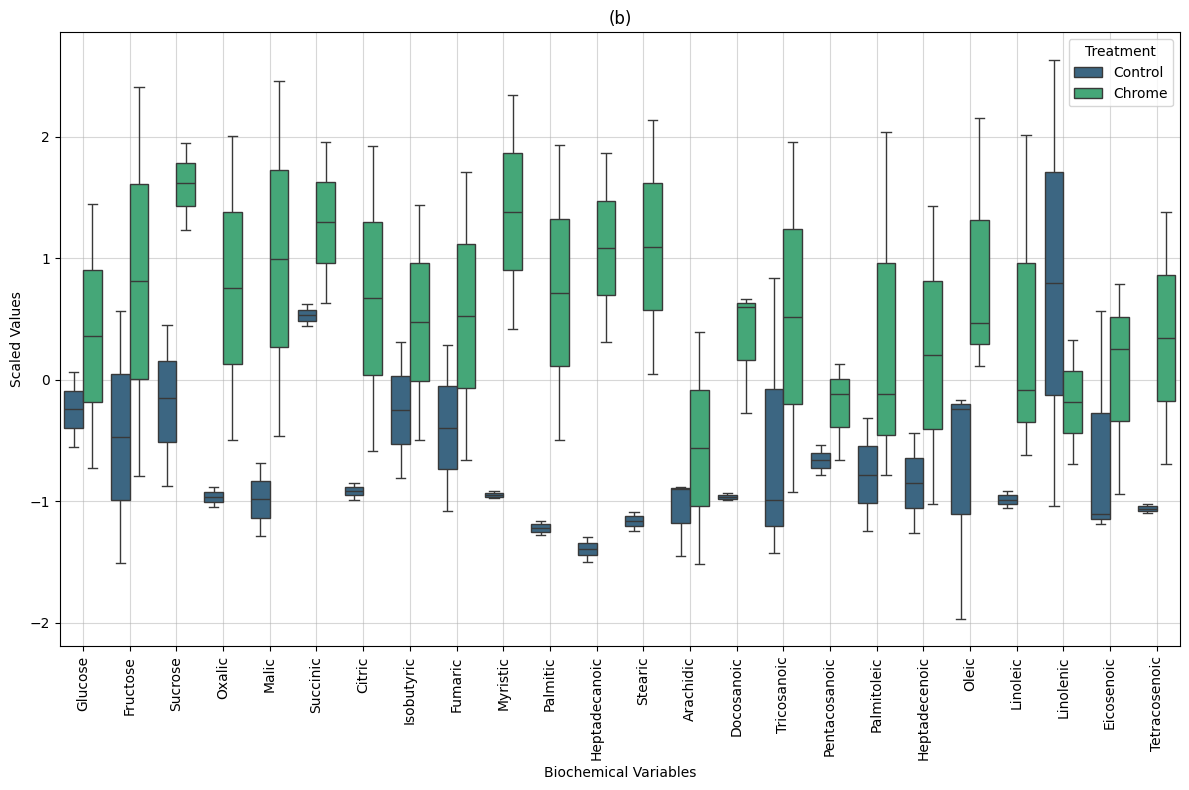

In [6]:
plt.figure(figsize=(12, 8))

# Filter the dataframe for 'AT' plants
df_at = X_scaled_df_info[X_scaled_df_info['Plant Abbr'] == 'SO'].copy()

# Melt the dataframe to long format, suitable for plotting multiple variables with hue
df_melted_at = df_at.melt(id_vars=['Treatment', 'Plant Abbr'], var_name='Biochemical Variable', value_name='Scaled Value')

# Generate the boxplot with 'Treatment' as hue
sns.boxplot(data=df_melted_at, x='Biochemical Variable', y='Scaled Value', hue='Treatment', palette='viridis')
plt.title('(b)')
plt.xlabel('Biochemical Variables')
plt.ylabel('Scaled Values')
plt.xticks(rotation=90)
plt.grid(alpha=0.5)
plt.tight_layout() # Adjust layout to prevent labels from overlapping
plt.show()

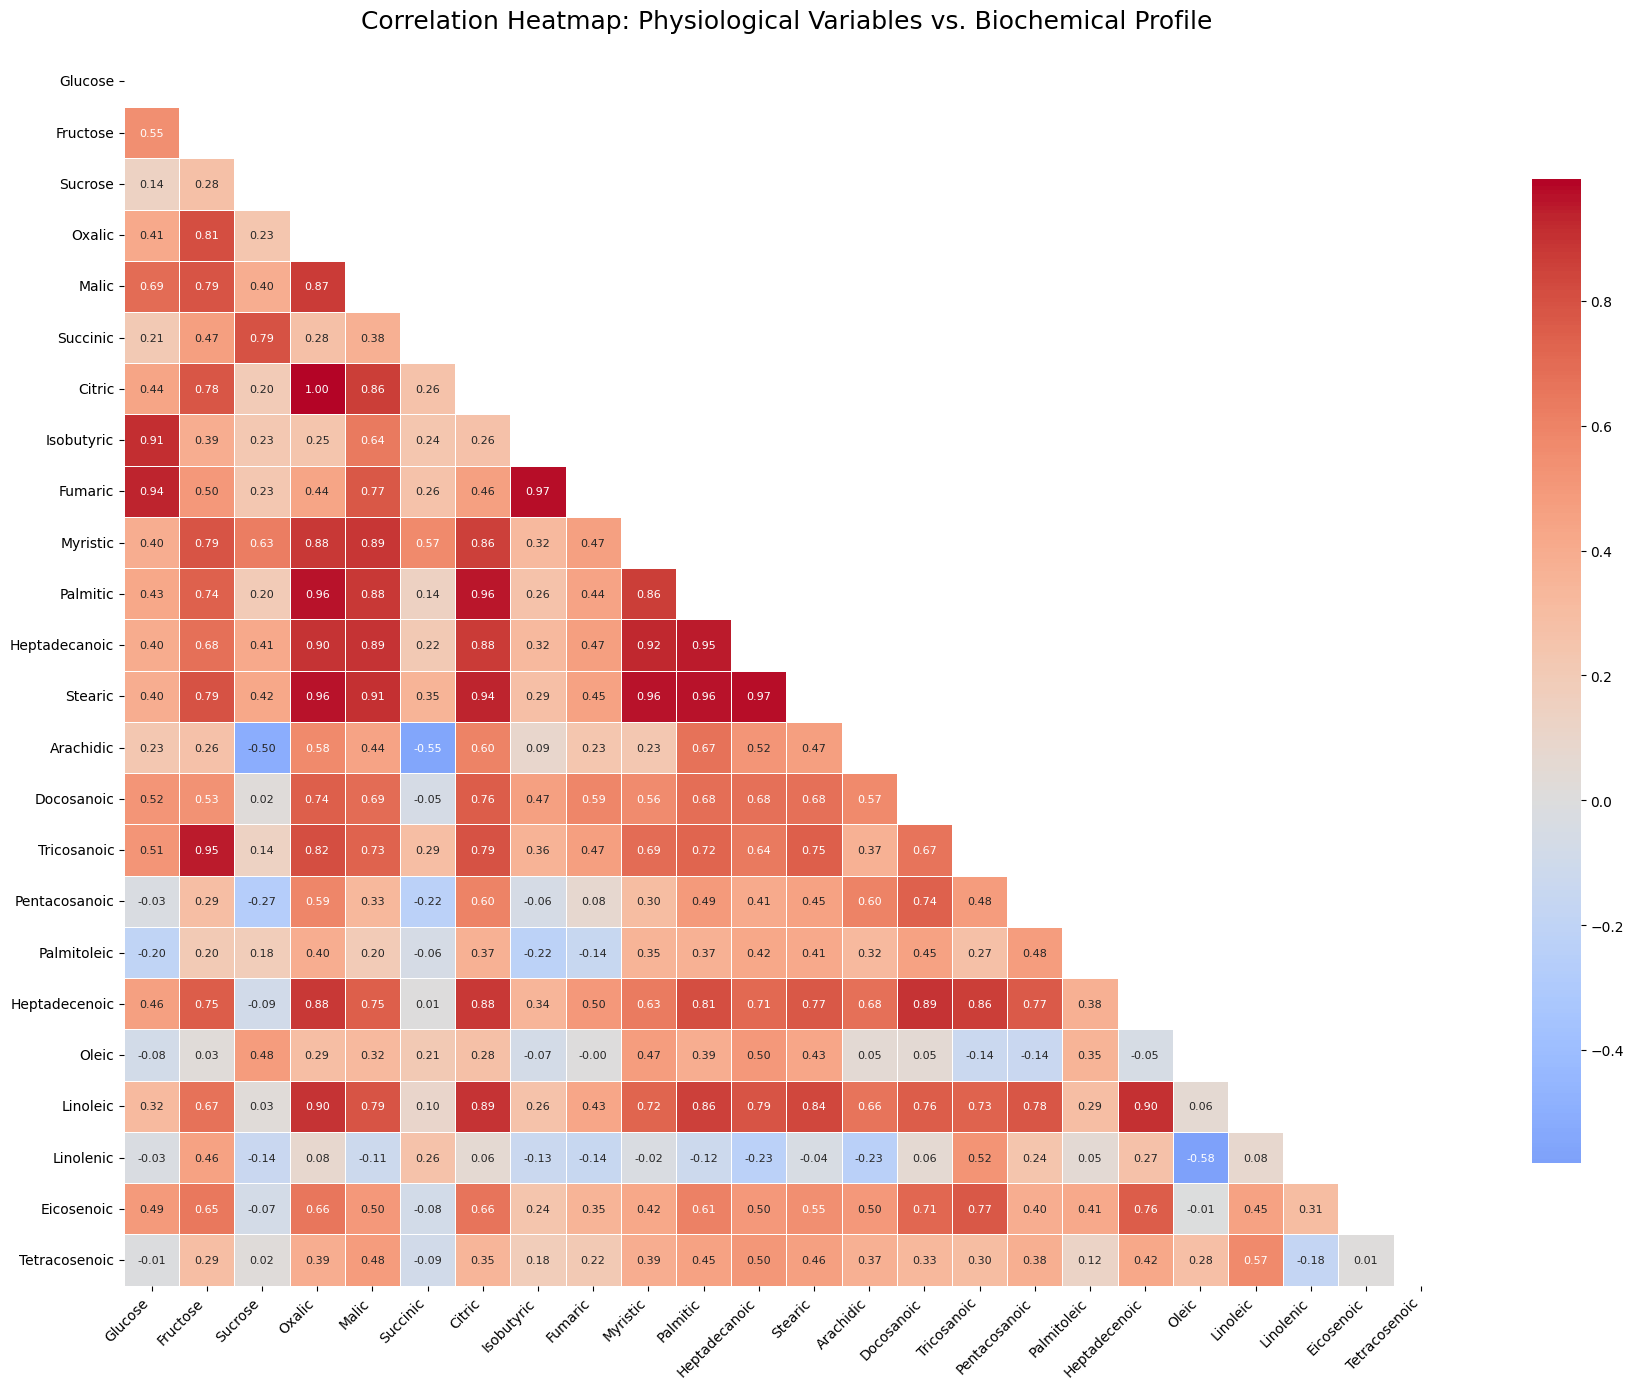

In [8]:
corr_matrix = X_scaled_df.corr()

plt.figure(figsize=(18, 14))

mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

heatmap = sns.heatmap(corr_matrix,
                      mask=mask,
                      annot=True,
                      fmt=".2f",
                      cmap='coolwarm',
                      center=0,
                      linewidths=.5,
                      cbar_kws={"shrink": .8},
                      annot_kws={"size": 8})

plt.title('Correlation Heatmap: Physiological Variables vs. Biochemical Profile', fontsize=18, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Salvar e mostrar
plt.show()

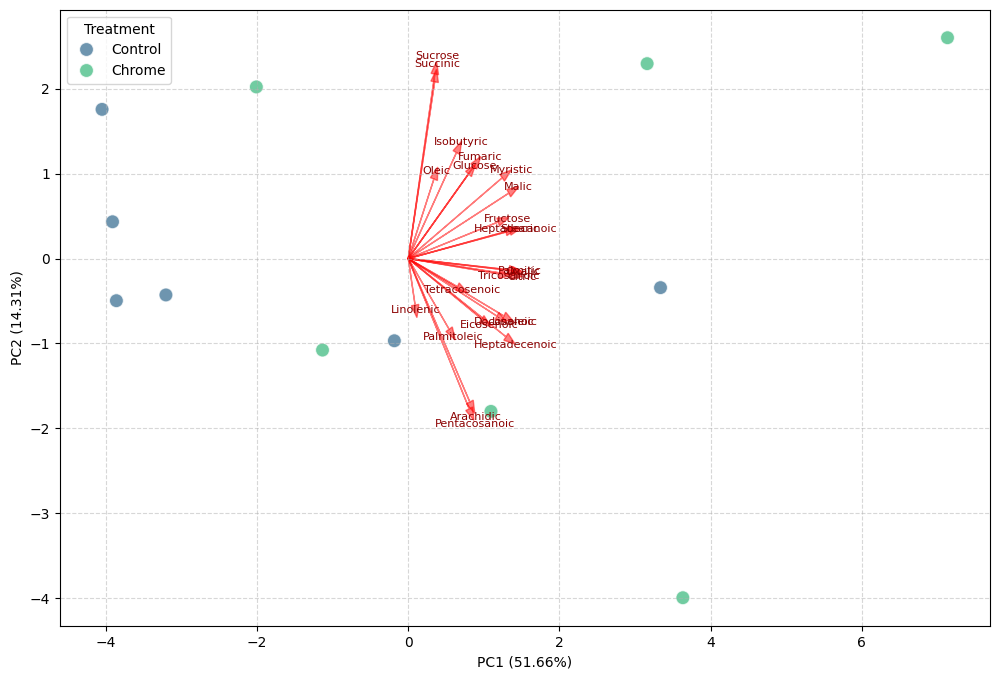

In [9]:
pca = PCA(n_components=2)
pca_results = pca.fit_transform(X_scaled)

def plot_pca_biplot(score, coeff, labels=None, groups=None):
    plt.figure(figsize=(12, 8))
    sns.scatterplot(x=score[:, 0], y=score[:, 1], hue=groups, palette='viridis', s=100, alpha=0.7)

    scale_factor = 5.0
    for i in range(coeff.shape[0]):
        plt.arrow(0, 0, coeff[i, 0]*scale_factor, coeff[i, 1]*scale_factor, color='red', alpha=0.5, head_width=0.1)
        if labels is not None:
            plt.text(coeff[i, 0]*scale_factor * 1.1, coeff[i, 1]*scale_factor * 1.1, labels[i],
                     color='darkred', ha='center', va='center', fontsize=8)

    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

plot_pca_biplot(pca_results, pca.components_.T, labels=X.columns, groups=y_class)

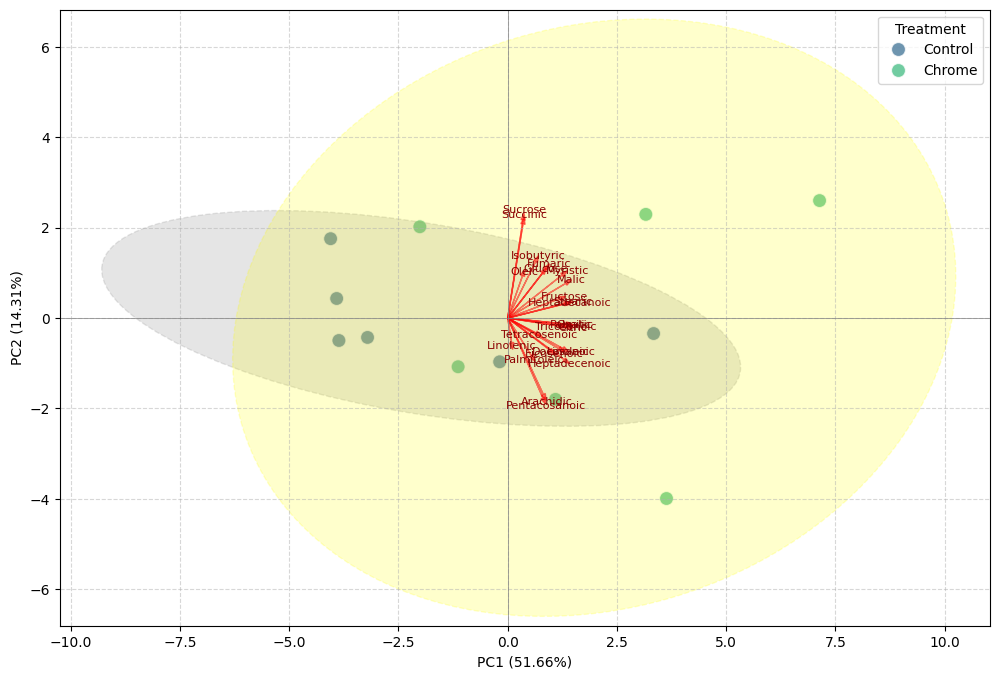

In [10]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2

pca = PCA(n_components=2)
pca_results = pca.fit_transform(X_scaled)

def plot_pca_biplot(score, coeff, labels=None, groups=None):
    plt.figure(figsize=(12, 8))

    sns.scatterplot(x=score[:, 0], y=score[:, 1], hue=groups, palette='viridis', s=100, alpha=0.7)

    ax = plt.gca()
    color = ['gray','yellow']
    i = 0
    for group_name in groups.unique():
        group_scores = score[groups == group_name]

        mean = np.mean(group_scores, axis=0)
        covariance = np.cov(group_scores, rowvar=False)

        eigenvalues, eigenvectors = np.linalg.eigh(covariance)

        angle = np.degrees(np.arctan2(eigenvectors[1, 0], eigenvectors[0, 0]))

        confidence_multiplier = np.sqrt(chi2.ppf(0.95, 2))

        width = 2 * confidence_multiplier * np.sqrt(eigenvalues[0])
        height = 2 * confidence_multiplier * np.sqrt(eigenvalues[1])

        ellipse = Ellipse(xy=mean, width=width, height=height,
                          angle=angle, color=color[i], alpha=0.2, linestyle='--')
        ax.add_patch(ellipse)

        i += 1

    scale_factor = 5.0
    for i in range(coeff.shape[0]):
        plt.arrow(0, 0, coeff[i, 0]*scale_factor, coeff[i, 1]*scale_factor, color='red', alpha=0.5, head_width=0.1)
        if labels is not None:
            plt.text(coeff[i, 0]*scale_factor * 1.1, coeff[i, 1]*scale_factor * 1.1, labels[i],
                     color='darkred', ha='center', va='center', fontsize=8)

    plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%})')
    plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%})')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.axhline(0, color='gray', lw=0.5)
    plt.axvline(0, color='gray', lw=0.5)
    plt.show()

plot_pca_biplot(pca_results, pca.components_.T, labels=X.columns, groups=y_class)

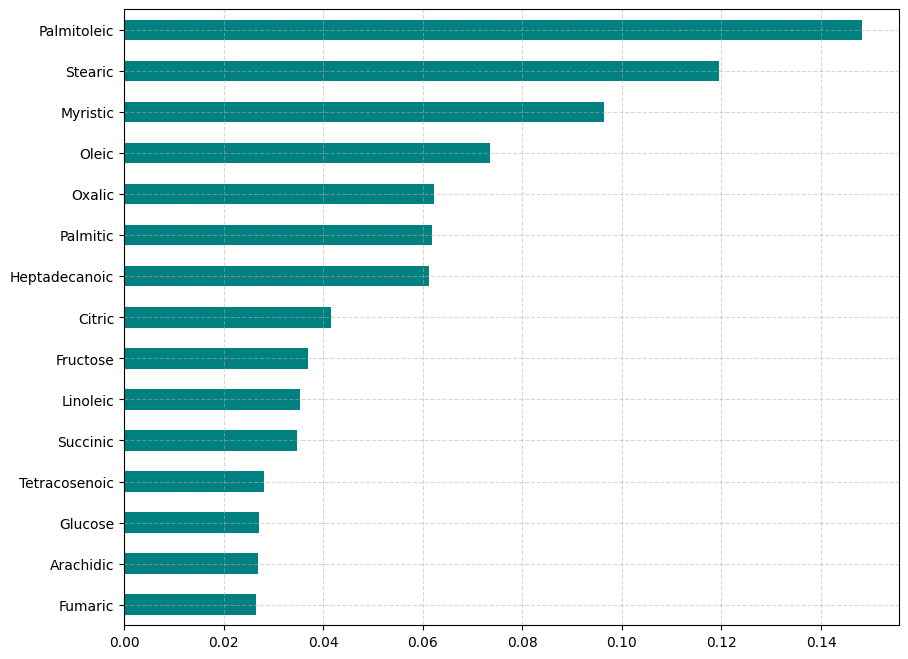

In [11]:
cv_strategy = KFold(n_splits=10, shuffle=True, random_state=42)
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=cv_strategy)
grid_rf.fit(X_scaled, y_class)

importances = pd.Series(grid_rf.best_estimator_.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(10, 8))
importances.head(15).plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

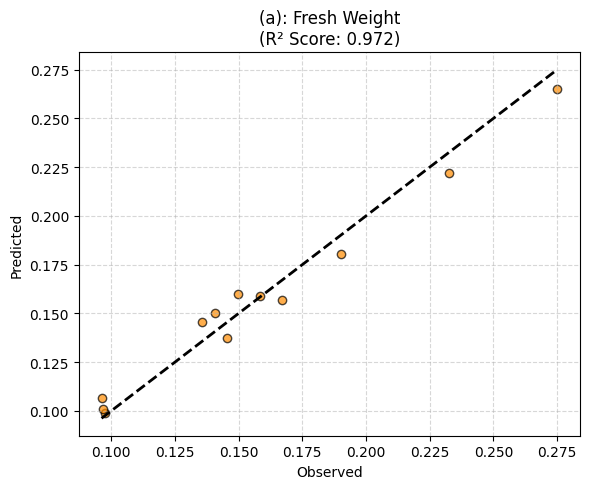

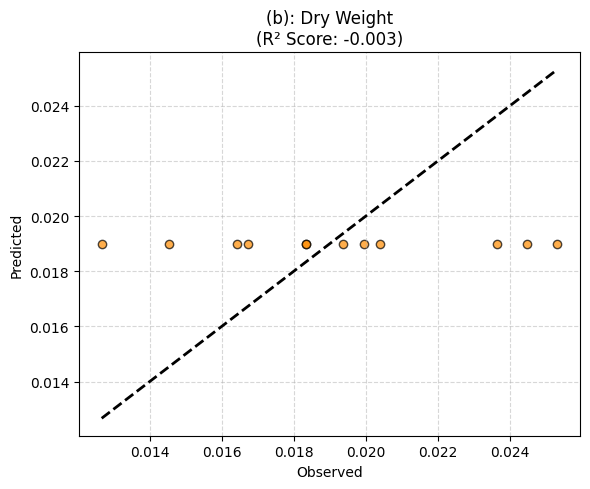

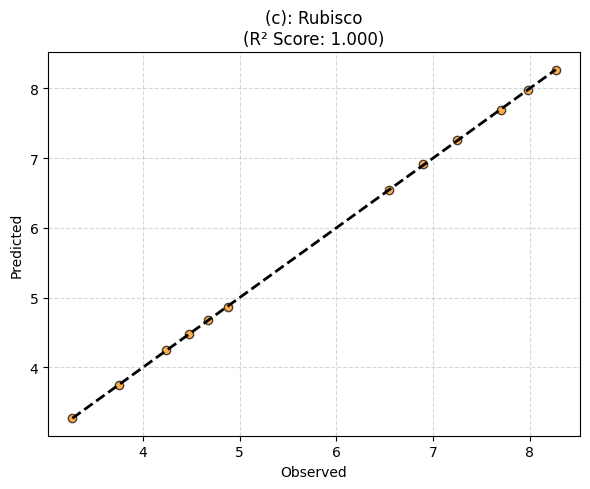

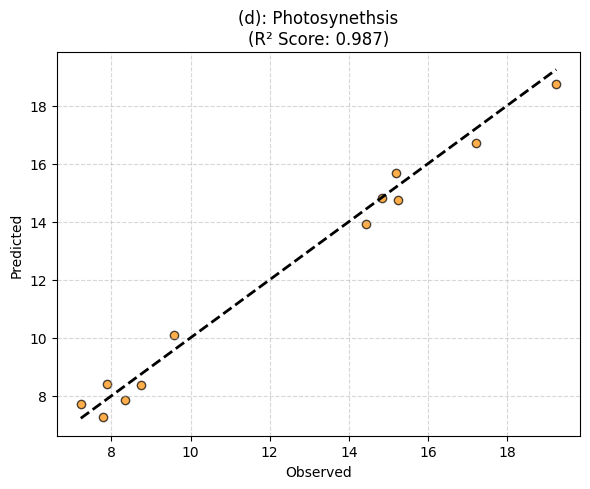

In [12]:
param_grid_svr = {'C': [0.1, 1, 10, 100], 'epsilon': [0.01, 0.1, 0.5], 'kernel': ['rbf', 'linear']}

labels = ['a','b','c','d']
i = 0

for target in targets_reg:
    y = df[target]
    grid_svr = GridSearchCV(SVR(), param_grid_svr, cv=5, scoring='r2')
    grid_svr.fit(X_scaled, y)

    y_pred = grid_svr.best_estimator_.predict(X_scaled)
    r2 = r2_score(y, y_pred)

    plt.figure(figsize=(6, 5))
    plt.scatter(y, y_pred, alpha=0.7, color='darkorange', edgecolors='k')
    plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
    plt.title('(' + labels[i] + ')' + f': {target}\n(R² Score: {r2:.3f})')
    plt.xlabel('Observed')
    plt.ylabel('Predicted')
    plt.tight_layout()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.show()

    i = i + 1